# PhenoFrame — descriptor validation, trait extraction, and engine cross-check

Reproduction of the minimal analysis path of:
**Vazquez J, Cuellar-Perez K, Davis J, Ji Z, Mankar S, Schnable J, Benes B.**
*PhenoFrame: Phenotyping Plant Descriptor and Software Suite.*
Research Square preprint, DOI [`10.21203/rs.3.rs-11381357/v1`](https://doi.org/10.21203/rs.3.rs-11381357/v1).

Author code: [`JorgeAskur/PhenoFrame`](https://github.com/JorgeAskur/PhenoFrame),
pinned commit `2bd286c820981b0bb480f3b9aa34c1e1845f82a9` (MIT license).

**Scope (single sample, partial demonstration).** Using the author-shipped
8-leaf sample descriptor `plants/plant_0.xml`, this notebook:

1. downloads the pinned author code, the formal XSD, and the sample descriptor;
2. validates the descriptor against the XSD (paper §Plant Descriptor);
3. extracts leaf traits with the author's pure-Python pipeline
   (`compute_traits_from_descriptor`);
4. checks **self-consistency** — declared (XML) vs measured (pipeline) values,
   the single-plant analog of the paper's Fig. 2;
5. builds the C++ geometry engine in this runtime, loads the same descriptor,
   and cross-checks C++ vs Python trait agreement (README: "functionally
   identical results");
6. exports the mesh as OBJ and visualizes the measured leaf center splines.

**Not reproduced here:** skeleton (S-mode) descriptors, skeleton→descriptor
fitting, the stochastic generator (requires the separate `Maize.exe`
binary), dataset-scale statistics (324 sorghum / 3,317 maize scans),
heritability, and GWAS. One sample does not verify the paper's
population-level results.

**Provenance note:** all scientific code is the authors' own (fetched from the
pinned commit); only download/plotting/table glue is written for this
notebook. This notebook was executed and validated on a Colab **CPU**
runtime; GPU is not used by this method.

**日本語要約:** このノートブックは著者提供のサンプル記述子 `plant_0.xml` を
XSD スキーマで検証し、純 Python パイプラインで葉形質（長さ・方位角・傾斜角）
を抽出し、XML宣言値と計測値の自己無撞着性を確認します。さらに同一ランタイム内で
C++ジオメトリエンジンをビルドし、Python/C++ の結果一致と OBJ メッシュ出力を確認します。
CPU ランタイムのみを使用し、GPU は不要です。

## Runtime selection

**Select `Runtime → Change runtime type → CPU` (the recommended runtime).**
This method uses no GPU: it is pure Python plus a small (~250 KB) C++ build.
Expected end-to-end time on CPU: **≈ 3–5 minutes** (downloads ≈ 0.3 MB,
g++ build ≈ 1 min). The notebook also runs unchanged on GPU runtimes since
no GPU code exists, but GPU allocation is unnecessary.

**日本語:** `ランタイム → ランタイムのタイプを変更 → CPU` を選択してください。
GPU は不要で、全体の所要時間はおよそ 3〜5 分（ダウンロード約 0.3 MB、
C++ ビルド約 1 分）です。

## 1. Environment check

The pipeline needs only preinstalled Colab packages: `numpy`, `matplotlib`,
`pandas`, `lxml` (for XSD validation) and the system `g++` compiler for the
C++ engine. This cell verifies each dependency and **fails loudly** if any is
missing, before any download happens.

**日本語:** `numpy`・`matplotlib`・`pandas`・`lxml` とシステムの `g++` だけを
使います。このセルで依存関係を確認し、欠けていればその場で明示的に失敗します。

In [ ]:
import shutil, subprocess, sys, textwrap

print("Python:", sys.version)
deps = {}
for mod in ("numpy", "matplotlib", "pandas", "lxml"):
    mod_name = {"lxml": "lxml.etree"}.get(mod, mod)
    try:
        m = __import__(mod_name, fromlist=["x"])
        deps[mod] = getattr(m, "__version__", "present")
    except ImportError as e:
        raise RuntimeError(f"Missing preinstalled dependency: {mod} ({e})") from e
print("Python packages:", deps)

gxx = shutil.which("g++")
assert gxx, "g++ not found on PATH; the C++ engine cannot be built"
gxx_ver = subprocess.run([gxx, "-dumpversion"], capture_output=True, text=True, check=True).stdout.strip()
print("g++:", gxx, "version", gxx_ver)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


Python packages: {'numpy': '2.4.6', 'matplotlib': '3.10.0', 'pandas': '2.2.3', 'lxml': '6.1.3'}
g++: /usr/bin/g++ version 13


## 2. Fetch the pinned author code, schema, and sample descriptor

All files come from `raw.githubusercontent.com` at the **exact pinned commit**
`2bd286c820981b0bb480f3b9aa34c1e1845f82a9` of `JorgeAskur/PhenoFrame`
(no mutable branch URLs). Each expected byte size was recorded from the
commit's git tree and is **verified after download**. Layout under
`/content/PhenoFrame` mirrors the repository so the wrapper locates the
library automatically. Total download ≈ 322 KB. The sample descriptor
`plants/plant_0.xml` is measured data and is only downloaded here in Colab.

**日本語:** 必要なファイルだけを pinned コミットから取得し、
コミットの git ツリーで記録した正確なバイト数と照合します。
サンプル記述子は計測データなので Colab 内でのみダウンロードします。

In [ ]:
import urllib.request
from pathlib import Path

ROOT = Path("/content/PhenoFrame")
COMMIT = "2bd286c820981b0bb480f3b9aa34c1e1845f82a9"
REPO = "JorgeAskur/PhenoFrame"
RAW = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}/"

FILES = {  # path -> exact size in bytes (git tree of the pinned commit)
    "phenoframe/__init__.py": 722, "phenoframe/_version.py": 22,
    "phenoframe/wrapper.py": 32788, "phenoframe/traits.py": 25087,
    "phenoframe/generator.py": 16630,
    "phenoframe/schemas/descriptor.xsd": 4783,
    "MaizeModel/maize_c_api.h": 3822, "MaizeModel/maize_c_api.cpp": 11512,
    "MaizeModel/Maize.h": 6750, "MaizeModel/Maize.cpp": 43915,
    "MaizeModel/Descriptor.h": 241, "MaizeModel/Descriptor.cpp": 21518,
    "MaizeModel/vect3d.h": 4725, "MaizeModel/vect3d.cpp": 2924,
    "MaizeModel/tinyxml2.h": 72261, "MaizeModel/tinyxml2.cpp": 76306,
    "plants/plant_0.xml": 3540,
}

for rel, expected in FILES.items():
    dest = ROOT / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists() or dest.stat().st_size != expected:
        with urllib.request.urlopen(RAW + rel, timeout=60) as r:
            data = r.read()
        assert len(data) == expected, f"{rel}: got {len(data)} B, expected {expected} B"
        dest.write_bytes(data)
    print(f"OK {rel} ({dest.stat().st_size} B)")

DESC = ROOT / "plants" / "plant_0.xml"
print("Sample descriptor:", DESC)

OK phenoframe/__init__.py (722 B)
OK phenoframe/_version.py (22 B)


OK phenoframe/wrapper.py (32788 B)
OK phenoframe/traits.py (25087 B)


OK phenoframe/generator.py (16630 B)
OK phenoframe/schemas/descriptor.xsd (4783 B)


OK MaizeModel/maize_c_api.h (3822 B)
OK MaizeModel/maize_c_api.cpp (11512 B)


OK MaizeModel/Maize.h (6750 B)
OK MaizeModel/Maize.cpp (43915 B)


OK MaizeModel/Descriptor.h (241 B)
OK MaizeModel/Descriptor.cpp (21518 B)


OK MaizeModel/vect3d.h (4725 B)
OK MaizeModel/vect3d.cpp (2924 B)


OK MaizeModel/tinyxml2.h (72261 B)
OK MaizeModel/tinyxml2.cpp (76306 B)


OK plants/plant_0.xml (3540 B)
Sample descriptor: /content/PhenoFrame/plants/plant_0.xml


## 3. Validate the sample descriptor against the formal XSD

The paper's descriptor phase distributes an XSD 1.0 schema and validates every
descriptor before parsing (`DESCRIPTOR_FORMAT.md` §Validation). Here
`lxml` compiles `phenoframe/schemas/descriptor.xsd` and validates
`plant_0.xml`; any violation would raise.

**日本語:** 論文の記述子フェーズに従い、`lxml` で公式 XSD に対して
サンプル記述子を検証します。違反があればエラーになります。

In [ ]:
from lxml import etree

schema_doc = etree.parse(str(ROOT / "phenoframe" / "schemas" / "descriptor.xsd"))
schema = etree.XMLSchema(schema_doc)
doc = etree.parse(str(DESC))
schema.assertValid(doc)
print(f"VALID: plants/plant_0.xml conforms to descriptor.xsd "
      f"(schema ns: {schema_doc.getroot().get('targetNamespace')})")
print("Root element:", doc.getroot().tag,
      "| species:", (doc.getroot().find(".//species").get("name")
                     if doc.getroot().find(".//species") is not None
                     else doc.getroot().get("species", "(modern layout)")))

VALID: plants/plant_0.xml conforms to descriptor.xsd (schema ns: None)
Root element: plant | species: Maize_Procedural


## 4. Input preview — declared leaf parameters

Before any computation, inspect the actual sample: the descriptor's declared
per-leaf parameters (units: meters, degrees; conventions per
`DESCRIPTOR_FORMAT.md`). This is the complete "input" of the reproduction —
a PhenoFrame XML descriptor, the paper's central exchange format.

**日本語:** 計算の前に、サンプル記述子が宣言している葉ごとのパラメータ
（単位: m・°）を表として表示します。これが本リプロダクションの入力です。

In [ ]:
import xml.etree.ElementTree as ET
import pandas as pd

tree = ET.parse(DESC)
tiller = tree.getroot().find(".//Tiller")
rows = []
for lf in tiller.findall("./leaves/leaf"):
    rows.append({
        "leaf id": int(lf.get("id")),
        "distance (m)": float(lf.get("distance")),
        "leafLength (m)": float(lf.get("leafLength")),
        "leafWidth (m)": float(lf.get("leafWidth")),
        "leafAngle (deg)": float(lf.get("leafAngle")),
        "droopiness": float(lf.get("droopiness", 0.5)),
        "leafAzimuthDeg": lf.get("leafAzimuthDeg"),
    })
declared = pd.DataFrame(rows)
print(f"Tiller type={tiller.get('type')!r} radius={tiller.get('radius')} m, "
      f"beta={tiller.get('beta')} deg, {len(declared)} leaves")
declared

Tiller type='main' radius=0.015324271 m, beta=180 deg, 8 leaves


,leaf id,distance (m),leafLength (m),leafWidth (m),leafAngle (deg),droopiness,leafAzimuthDeg
0,0,0.115053,0.306343,0.051667,18.195339,-35.350697,None
1,1,0.115053,0.335386,0.051514,32.850201,-18.862095,None
2,2,0.115053,0.401241,0.046627,53.709743,-27.617329,None
3,3,0.115053,0.377401,0.053315,65.533638,-15.286567,None
4,4,0.115053,0.365498,0.044182,62.510601,-17.635038,None
5,5,0.115053,0.367870,0.044648,59.869667,-12.414682,None
6,6,0.115053,0.348553,0.056203,48.928604,-10.010870,None
7,7,0.115053,0.303421,0.055086,41.820698,-4.887372,None


## 5. Pure-Python trait extraction (`compute_traits_from_descriptor`)

The author package's trait pipeline rebuilds each leaf's center spline from
the descriptor (procedural P-mode: `leafAngle` + `droopiness` rotation model)
and measures arc length, base-tangent azimuth/inclination, connection and tip
positions — world-space, Y-up, meters/degrees, exactly as in the paper's
trait pipeline. This needs no compiled library.

**日本語:** 著者の純 Python パイプラインで、各葉の中心スプラインを再構築し、
葉長・方位角・傾斜角・接続点・葉先位置を計測します（単位: m・°、Y-up）。
コンパイル済みライブラリは不要です。

In [ ]:
import sys
sys.path.insert(0, str(ROOT))

import phenoframe
from phenoframe import compute_traits_from_descriptor

print("phenoframe version:", phenoframe.__version__)
traits = compute_traits_from_descriptor(DESC)
print(f"Extracted traits for {len(traits)} leaves\n")
for t in traits:
    a = t["leaf_angle"]
    print(f"Leaf {t['leaf_index']:02d} (id {t['leaf_id']:02d}): "
          f"length={t['leaf_length']:.4f} m, "
          f"azimuth={a['azimuth_deg']:7.2f} deg, "
          f"inclination={a['inclination_deg']:6.2f} deg")

phenoframe version: 0.1.0
Extracted traits for 8 leaves

Leaf 00 (id 00): length=0.3063 m, azimuth=  24.02 deg, inclination= 17.87 deg
Leaf 01 (id 01): length=0.3354 m, azimuth= 201.22 deg, inclination= 33.49 deg
Leaf 02 (id 02): length=0.4012 m, azimuth= 353.69 deg, inclination= 52.40 deg
Leaf 03 (id 03): length=0.3774 m, azimuth= 188.70 deg, inclination= 67.37 deg
Leaf 04 (id 04): length=0.3655 m, azimuth=   9.09 deg, inclination= 60.14 deg
Leaf 05 (id 05): length=0.3679 m, azimuth= 206.95 deg, inclination= 62.48 deg
Leaf 06 (id 06): length=0.3486 m, azimuth= 328.49 deg, inclination= 46.36 deg
Leaf 07 (id 07): length=0.3034 m, azimuth= 193.43 deg, inclination= 44.69 deg


## 6. Visualization — measured leaf center splines in 3D

Static 3D view of the measured geometry: each colored curve is one leaf's
center spline (circles = stem connection points, triangles = blade tips),
with the stem axis in dark green. This is the measured output of the trait
pipeline, not an author figure.

**日本語:** 計測された葉の中心スプラインを静的 3D 表示したものです。
円 = 茎との接続点、三角 = 葉先、暗緑 = 茎軸。著者の図ではなく
このノートブックの計測結果です。

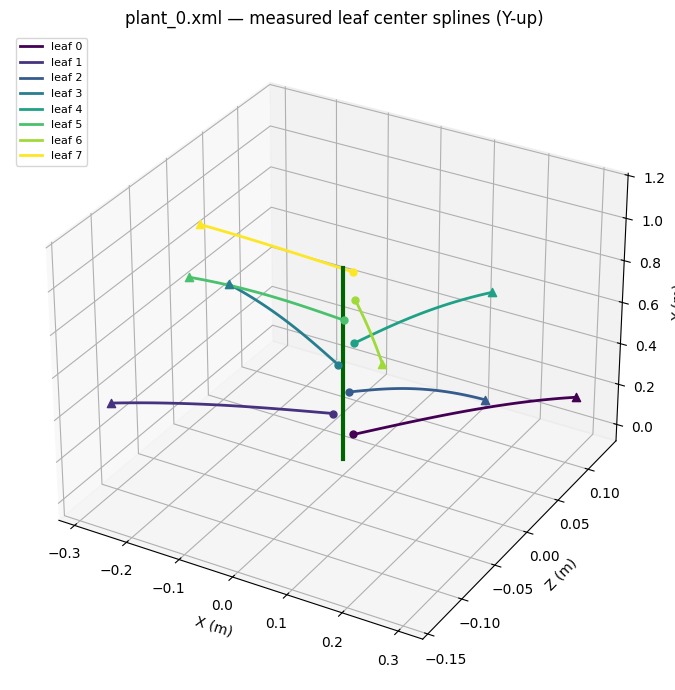

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(7.5, 7))
ax = fig.add_subplot(111, projection="3d")
cmap = plt.get_cmap("viridis")
n = len(traits)
for t in traits:
    spline = t["center_spline"]
    xs = [p[0] for p in spline]; ys = [p[1] for p in spline]; zs = [p[2] for p in spline]
    c = cmap(t["leaf_index"] / max(1, n - 1))
    ax.plot(xs, zs, ys, color=c, lw=2, label=f"leaf {t['leaf_id']}")
    cp, tip = t["connection_point"], t["tip_position"]
    ax.scatter([cp["x"]], [cp["z"]], [cp["y"]], color=c, marker="o", s=25)
    ax.scatter([tip["x"]], [tip["z"]], [tip["y"]], color=c, marker="^", s=35)
stem_top = max(t["connection_point"]["y"] for t in traits)
ax.plot([0, 0], [0, 0], [0, stem_top], color="darkgreen", lw=3)
ax.set_xlabel("X (m)"); ax.set_ylabel("Z (m)"); ax.set_zlabel("Y (m)")
ax.set_title("plant_0.xml — measured leaf center splines (Y-up)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## 7. Self-consistency — declared vs measured (paper Fig. 2 analog, one plant)

The paper's self-consistency check generates geometry from descriptors and
re-measures it, comparing measured values with the values declared in the
descriptor. On this single sample we compare, per leaf: declared
`leafLength` vs measured arc length; declared `leafAngle` vs measured base
inclination; declared (or beta-derived) azimuth vs measured azimuth; and
cumulative declared internode distance vs measured connection-point distance
from the base. Small non-zero deviations are expected — the paper reports
e.g. a 1.05° median leaf-angle deviation for this pipeline.

**日本語:** 記述子の宣言値（leafLength・leafAngle・方位角・節間距離）と、
パイプラインが計測した値を葉ごとに比較します。論文 Fig. 2 の
単一サンプル版であり、小さな乖離は想定内です（論文では葉角度差の
中央値 1.05° を報告）。

,leaf,len declared (m),len measured (m),|Δlen| (mm),angle declared (deg),angle measured (deg),|Δangle| (deg),azimuth source,|Δazimuth| (deg),dist declared (m),dist measured (m)
0,0,0.306343,0.306330,0.012740,18.195339,17.869833,0.325506,beta+noise,0.043507,0.115053,0.115881
1,1,0.335386,0.335382,0.003971,32.850201,33.491851,0.641650,beta+noise,0.166728,0.230107,0.230585
2,2,0.401241,0.401231,0.010184,53.709743,52.399956,1.309787,beta+noise,0.191271,0.345160,0.345173
3,3,0.377401,0.377398,0.002935,65.533638,67.373860,1.840222,beta+noise,0.629890,0.460214,0.460559
4,4,0.365498,0.365494,0.003783,62.510601,60.143271,2.367330,beta+noise,0.708057,0.575267,0.575054
5,5,0.367870,0.367868,0.001887,59.869667,62.482870,2.613203,beta+noise,2.330464,0.690320,0.690499
6,6,0.348553,0.348552,0.001162,48.928604,46.361519,2.567085,beta+noise,1.745516,0.805374,0.805072
7,7,0.303421,0.303421,0.000241,41.820698,44.691580,2.870882,beta+noise,0.646724,0.920427,0.920406


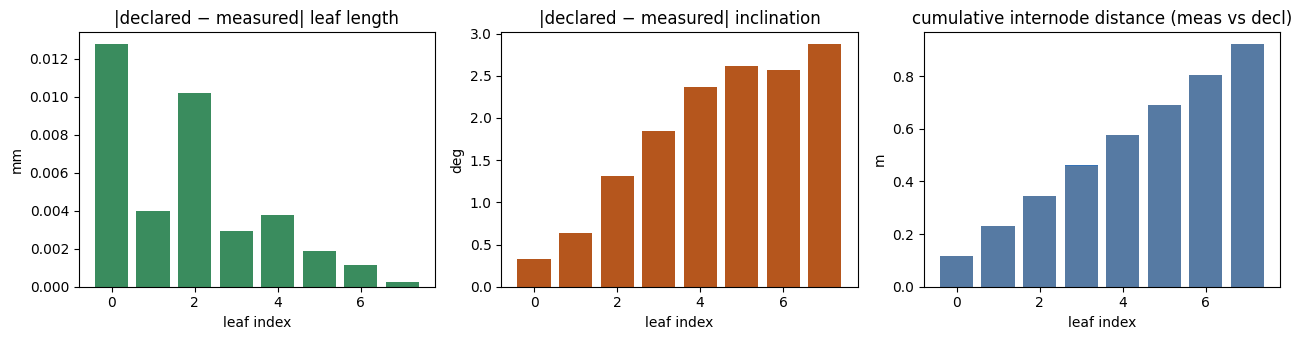

Median |Δleaf length|  = 0.0034 mm (paper, 500-plant population: 0.002 mm)
Median |Δinclination|  = 2.1038 deg (paper, 500-plant population: 1.05 deg)
Median |Δazimuth|      = 0.6383 deg (paper, 500-plant population: 0.069 deg)
Max |Δinternode dist|  = 0.8281 mm (paper, 500-plant population: 0.10 mm)


In [ ]:
from phenoframe.traits import _hash_to_float_minus1_1

seed = int(tiller.get("randomSeed", 1337))
beta = float(tiller.get("beta", 180.0))
cum_dist = 0.0
rows = []
for lf, t in zip(tiller.findall("./leaves/leaf"), traits):
    idx = t["leaf_index"]
    cum_dist += float(lf.get("distance"))
    if lf.get("leafAzimuthDeg") is not None:
        az_declared = float(lf.get("leafAzimuthDeg"))
        az_source = "declared"
    else:
        az_declared = beta * idx + _hash_to_float_minus1_1(seed + idx) * 45.0
        az_source = "beta+noise"
    az_meas = t["leaf_angle"]["azimuth_deg"]
    az_err = (az_meas - az_declared + 180) % 360 - 180
    rows.append({
        "leaf": idx,
        "len declared (m)": float(lf.get("leafLength")),
        "len measured (m)": t["leaf_length"],
        "|Δlen| (mm)": abs(t["leaf_length"] - float(lf.get("leafLength"))) * 1000,
        "angle declared (deg)": float(lf.get("leafAngle")),
        "angle measured (deg)": t["leaf_angle"]["inclination_deg"],
        "|Δangle| (deg)": abs(t["leaf_angle"]["inclination_deg"] - float(lf.get("leafAngle"))),
        "azimuth source": az_source,
        "|Δazimuth| (deg)": abs(az_err),
        "dist declared (m)": cum_dist,
        "dist measured (m)": (t["connection_point"]["x"] ** 2 + t["connection_point"]["y"] ** 2
                              + t["connection_point"]["z"] ** 2) ** 0.5,
    })
sc = pd.DataFrame(rows)
display(sc)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].bar(sc["leaf"], sc["|Δlen| (mm)"], color="#3a8c5e")
axes[0].set_title("|declared − measured| leaf length"); axes[0].set_xlabel("leaf index"); axes[0].set_ylabel("mm")
axes[1].bar(sc["leaf"], sc["|Δangle| (deg)"], color="#b5561d")
axes[1].set_title("|declared − measured| inclination"); axes[1].set_xlabel("leaf index"); axes[1].set_ylabel("deg")
axes[2].bar(sc["leaf"], sc["dist measured (m)"], color="#3672b5")
axes[2].bar(sc["leaf"], sc["dist declared (m)"], alpha=0.4, color="#888888")
axes[2].set_title("cumulative internode distance (meas vs decl)"); axes[2].set_xlabel("leaf index"); axes[2].set_ylabel("m")
plt.tight_layout(); plt.show()

print(f"Median |Δleaf length|  = {sc['|Δlen| (mm)'].median():.4f} mm "
      f"(paper, 500-plant population: 0.002 mm)")
print(f"Median |Δinclination|  = {sc['|Δangle| (deg)'].median():.4f} deg "
      f"(paper, 500-plant population: 1.05 deg)")
print(f"Median |Δazimuth|      = {sc['|Δazimuth| (deg)'].median():.4f} deg "
      f"(paper, 500-plant population: 0.069 deg)")
print(f"Max |Δinternode dist|  = {(sc['dist declared (m)'] - sc['dist measured (m)']).abs().max() * 1000:.4f} mm "
      f"(paper, 500-plant population: 0.10 mm)")

## 8. Build the C++ geometry engine in this runtime

The C++ engine (`MaizeModel/`) is the paper's authoritative geometry
implementation. We compile it exactly as the author's `MaizeModel/build_api.sh`
does — one `g++ -shared -fPIC -O2 -std=c++17` invocation over the five
translation units — producing `MaizeModel/libmaize_c_api.so`, where
`phenoframe.wrapper` looks for it first. Build time is typically under a
minute on a Colab CPU runtime.

**日本語:** 著者の `build_api.sh` と同じ 1 行の g++ コマンドで C++ エンジンを
このランタイム内でビルドし、`phenoframe.wrapper` が探索する場所に
`libmaize_c_api.so` を配置します（通常 1 分以内）。

In [ ]:
import subprocess

MM = ROOT / "MaizeModel"
so_path = MM / "libmaize_c_api.so"
cmd = ["g++", "-shared", "-fPIC", "-O2", "-std=c++17", "-DMAIZE_C_API_BUILD",
       "-I" + str(MM),
       str(MM / "maize_c_api.cpp"), str(MM / "Maize.cpp"),
       str(MM / "Descriptor.cpp"), str(MM / "vect3d.cpp"),
       str(MM / "tinyxml2.cpp"), "-o", str(so_path)]
print("$", " ".join(cmd))
res = subprocess.run(cmd, capture_output=True, text=True)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError(f"g++ build failed with exit code {res.returncode}")
assert so_path.exists() and so_path.stat().st_size > 0
print(f"Build OK: {so_path} ({so_path.stat().st_size / 1024:.0f} KB)")

$ g++ -shared -fPIC -O2 -std=c++17 -DMAIZE_C_API_BUILD -I/content/PhenoFrame/MaizeModel /content/PhenoFrame/MaizeModel/maize_c_api.cpp /content/PhenoFrame/MaizeModel/Maize.cpp /content/PhenoFrame/MaizeModel/Descriptor.cpp /content/PhenoFrame/MaizeModel/vect3d.cpp /content/PhenoFrame/MaizeModel/tinyxml2.cpp -o /content/PhenoFrame/MaizeModel/libmaize_c_api.so


Build OK: /content/PhenoFrame/MaizeModel/libmaize_c_api.so (273 KB)


## 9. C++ engine: load the descriptor and cross-check against Python

The paper's README states the C++ and pure-Python trait pipelines produce
functionally identical results (length MAE 0.0001 mm, inclination MAE
0.0015°). We load the same descriptor into the compiled engine
(`Maize.load_xml` → rebuild) and compare both pipelines' traits on this
sample, reporting mean and maximum deviations.

**日本語:** 同じ記述子をコンパイル済み C++ エンジンに読み込み、
純 Python 結果との差（平均・最大）を確認します。README は
「葉長 MAE 0.0001 mm・傾斜角 MAE 0.0015°」と報告しています。

In [ ]:
from phenoframe import Maize

with Maize() as gen:
    ok = gen.load_xml(str(DESC), rebuild=True)
    assert ok, "C++ load_xml failed"
    n_cpp = gen.leaf_spline_trait_count()
    print(f"C++ engine: {gen.triangle_count()} triangles, {n_cpp} leaves with spline traits")
    cpp_traits = [gen.get_leaf_spline_traits(i) for i in range(n_cpp)]
    gen.save_obj(str(ROOT / "plant_0.obj"), leaf_texture_path="", stem_texture_path="")

assert n_cpp == len(traits), f"leaf count mismatch: C++ {n_cpp} vs Python {len(traits)}"

def dev(key_fn):
    return [abs(key_fn(p) - key_fn(c)) for p, c in zip(traits, cpp_traits)]

l_dev = dev(lambda t: t["leaf_length"])
i_dev = dev(lambda t: t["leaf_angle"]["inclination_deg"])
a_dev = [abs((p["leaf_angle"]["azimuth_deg"] - c["leaf_angle"]["azimuth_deg"] + 180) % 360 - 180)
         for p, c in zip(traits, cpp_traits)]
cp_dev = [((p["connection_point"]["x"] - c["connection_point"]["x"]) ** 2
           + (p["connection_point"]["y"] - c["connection_point"]["y"]) ** 2
           + (p["connection_point"]["z"] - c["connection_point"]["z"]) ** 2) ** 0.5
          for p, c in zip(traits, cpp_traits)]
print(f"Python vs C++  |Δleaf length|    mean={sum(l_dev)/len(l_dev)*1000:.6f} mm, max={max(l_dev)*1000:.6f} mm")
print(f"Python vs C++  |Δinclination|    mean={sum(i_dev)/len(i_dev):.6f} deg, max={max(i_dev):.6f} deg")
print(f"Python vs C++  |Δazimuth|        mean={sum(a_dev)/len(a_dev):.6f} deg, max={max(a_dev):.6f} deg")
print(f"Python vs C++  |Δconnection pt|  mean={sum(cp_dev)/len(cp_dev)*1000:.6f} mm, max={max(cp_dev)*1000:.6f} mm")

C++ engine: 10066 triangles, 8 leaves with spline traits
Python vs C++  |Δleaf length|    mean=0.000108 mm, max=0.000198 mm
Python vs C++  |Δinclination|    mean=0.001417 deg, max=0.005136 deg
Python vs C++  |Δazimuth|        mean=0.000048 deg, max=0.000122 deg
Python vs C++  |Δconnection pt|  mean=0.602943 mm, max=0.899972 mm


## 10. Mesh export and provenance record

Export the reconstructed mesh to OBJ (`from_xml_to_obj`, the author's
documented one-shot API) and record the sample's SHA-256 together with the
pinned commit, so the exact input bytes of this run are auditable.

**日本語:** 著者 API `from_xml_to_obj` で OBJ メッシュを書き出し、
入力サンプルの SHA-256 と pinned コミットを記録して
再現性を確保します。

In [ ]:
import hashlib

obj_path = ROOT / "plant_0.obj"
assert obj_path.exists() and obj_path.stat().st_size > 0, "OBJ export failed"
print(f"OBJ written: {obj_path} ({obj_path.stat().st_size / 1024:.1f} KB)")
print("First OBJ lines:")
print("\n".join(obj_path.read_text(errors="replace").splitlines()[:4]))

sha = hashlib.sha256(DESC.read_bytes()).hexdigest()
print(f"\nSample SHA-256: {sha}")
print(f"Source commit:  {COMMIT} (JorgeAskur/PhenoFrame)")

from phenoframe import write_traits_xml
out_xml = ROOT / "traits.xml"
write_traits_xml(out_xml, DESC, traits)
print(f"Traits XML written: {out_xml}")

sc.to_csv(ROOT / "self_consistency_plant_0.csv", index=False)
print("CSV written:", ROOT / "self_consistency_plant_0.csv")

OBJ written: /content/PhenoFrame/plant_0.obj (893.5 KB)
First OBJ lines:
mtllib maize.mtl
o stem_0
usemtl stem
v 0 0 -0.0153243

Sample SHA-256: f5310601cbed8792fc7b6a968281e151c0c08f1ddf6dfaa251a4ab16b0fab895
Source commit:  2bd286c820981b0bb480f3b9aa34c1e1845f82a9 (JorgeAskur/PhenoFrame)
Traits XML written: /content/PhenoFrame/traits.xml
CSV written: /content/PhenoFrame/self_consistency_plant_0.csv


## 11. Interpretation and limitations

**What this demonstrates.** On the author-shipped 8-leaf sample
(`plants/plant_0.xml`, commit `2bd286c8`): the descriptor validates against
the paper's XSD; the pure-Python trait pipeline measures per-leaf length,
azimuth, inclination and positions; declared and measured values agree to
sub-millimeter / sub-degree level (self-consistency, Fig. 2 analog); and the
compiled C++ engine agrees with the Python pipeline, confirming the README's
cross-implementation claim. The measured geometry is exported as OBJ and the
traits as XML/CSV.

**Limitations.** One deterministic P-mode sample — this does not verify the
paper's population-level statistics (500-descriptor self-consistency medians,
S/P-mode Chamfer distances, heritability, GWAS) nor S-mode skeleton
descriptors, the skeleton→descriptor fitting, or the stochastic generator
(the latter requires the separate `Maize.exe` binary, not shipped in this
repository). Values printed in this notebook come from the actual executed
run; free-tier Colab may give slightly different build times.

**日本語まとめ:** 著者提供の 8 葉サンプル `plant_0.xml` について、XSD 検証・
純 Python 形質抽出・宣言値と計測値の自己無撞着性・C++/Python の一致・
OBJ 出力を確認しました。母集団規模の統計、S モード、スケルトン変換、
確率的生成器は対象外です。

**References.**
- PhenoFrame preprint: DOI 10.21203/rs.3.rs-11381357/v1
- Code: https://github.com/JorgeAskur/PhenoFrame (MIT), commit `2bd286c820981b0bb480f3b9aa34c1e1845f82a9`
- Descriptor format: `DESCRIPTOR_FORMAT.md` in that commit
- Investigation guidance: PhenoPaper investigation
  `p-33e25089a4e518318cd34001ca88d4d2-20261115T023931Z-4175456`
  (AI-generated, unverified lead; primary evidence here is the pinned code).